# Ranking Signals: Proximity, BM25F, and Anchor Text

For the query "uni basel", thousands of pages match both terms, and BM25 scores many of them
about equally. Classical retrieval treats every occurrence of a term as equal evidence and
ignores where it occurs. This notebook follows the book section *Ranking Signals Beyond Term
Counts* and computes its three content signals on the book's own examples: how close the
query terms are, in which HTML field they occur, and what other pages say in their links.

On the web, every signal also has to survive spammers. For each signal we therefore look at
the cheap trick that would fool a naive version, and at the design choice that stops it.

**Learning goals:**
- Merge positional hit lists, pair neighbouring hits of different terms, and compute a binned proximity score
- Count term occurrences per HTML field and score them with BM25F (weight, then saturate)
- See why saturating each field separately rewards keyword stuffing
- Build an anchor index and score anchors with one vote per domain

**Prerequisites:** Chapter 1 (BM25 and its saturation)

## Setup

In [1]:
import json
import math
import re
from collections import defaultdict
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from bs4 import BeautifulSoup

from shared.display import print_table, display_md

## 1. Term Proximity

The query "roger federer" is not a request for any page that contains "roger" and "federer".
A marathon result list with a Roger in row 12 and a Federer in row 4,000 matches both terms
but answers nothing. A **positional index** stores every position of a term in a document,
its **hit list**, and these positions tell the two cases apart.

As in the book, the document is the lead section of the English Wikipedia article on Roger
Federer. A fixed revision is stored with the demos, so the positions match the book. We split
the text into words and number them from 1.

In [2]:
article = json.loads(Path("data/ch08/federer_wikipedia_lead.json").read_text(encoding="utf-8"))

def tokenize(text):
    """Lowercase words; the position of a token is its index + 1."""
    return re.findall(r"\w+", text.lower())

def hit_lists(tokens, query):
    """Positions (1-based) of every query term in the token list."""
    terms = query.lower().split()
    return {t: [k + 1 for k, tok in enumerate(tokens) if tok == t] for t in terms}

tokens = tokenize(article["text"])
hits = hit_lists(tokens, "roger federer")

print_table([[f"\"{t}\"", ", ".join(map(str, pos))] for t, pos in hits.items()],
            headers=["term", "positions in D"])
display_md(
    f"*{article['source']}, revision {article['revision']} ({article['timestamp'][:10]}), "
    f"{article['license'].split(' (')[0]}.* The lead has **{len(tokens)} words**. "
    f"The full cross product of the hit lists has "
    f"{len(hits['roger']) * len(hits['federer'])} pairs, most of them meaningless."
)

| term      | positions in D                                                         |
|:----------|:-----------------------------------------------------------------------|
| "roger"   | 1, 532                                                                 |
| "federer" | 2, 57, 119, 165, 184, 235, 279, 337, 373, 419, 472, 509, 533, 560, 619 |

*English Wikipedia, lead section (plain text, pronunciation guide removed), revision 1381952651 (2026-10-25), CC BY-SA 4.0.* The lead has **626 words**. The full cross product of the hit lists has 30 pairs, most of them meaningless.

The article writes the full name only twice, at the start and in "the Roger Federer
Foundation". Everywhere else it uses the surname alone.

Instead of the full cross product, we **merge** both hit lists into one list sorted by
position and form a pair wherever two neighbouring entries belong to different terms
(Büttcher, Clarke, and Lushman, 2006). The rule treats both terms alike, needs no window
size, and works unchanged for three or more query terms.

In [3]:
def merged_pairs(hits):
    """Merge the hit lists by position; pair neighbouring hits of different terms."""
    merged = sorted((pos, term) for term, positions in hits.items() for pos in positions)
    return [(p1, t1, p2, t2) for (p1, t1), (p2, t2) in zip(merged, merged[1:]) if t1 != t2]

def show_pairs(tokens, hits, max_words=12):
    """One row per pair: positions, distance, order, and the text that links them."""
    terms = list(hits)
    rows = []
    for p1, t1, p2, t2 in merged_pairs(hits):
        span = tokens[p1 - 1:p2]
        text = " ".join(span) if len(span) <= max_words else " ".join(span[:5] + ["..."] + span[-5:])
        order = "in order" if terms.index(t1) < terms.index(t2) else "reversed"
        rows.append([f"({p1}, {p2})", p2 - p1, order, text])
    print_table(rows, headers=["pair", "distance", "order", "text"])

show_pairs(tokens, hits)

| pair       |   distance | order    | text                                                                                |
|:-----------|-----------:|:---------|:------------------------------------------------------------------------------------|
| (1, 2)     |          1 | in order | roger federer                                                                       |
| (509, 532) |         23 | reversed | federer played an instrumental role ... philanthropist having established the roger |
| (532, 533) |          1 | in order | roger federer                                                                       |

Three pairs, and position 532 belongs to two of them. The thirteen surname-only mentions form
no pair, since a pair needs both terms. The reversed pair (509, 532) links the end of one
mention to the start of the next, across a sentence boundary.

Next, bin $i$ counts the pairs at distance $i$ for $i = 1, \ldots, 10$. Pairs that are farther
apart are "not even close" and do not count. A decreasing weight vector turns the bins into a
score:

$$\text{score}_{\text{prox}}(Q, D) = \sum_{i=1}^{m} \text{bin}_i(Q, D) \cdot w_i \qquad \text{with } w_1 > w_2 > \ldots > w_m$$

In [4]:
PROX_WEIGHTS = (89, 55, 34, 21, 13, 8, 5, 3, 2, 1)

def proximity_score(hits, weights=PROX_WEIGHTS):
    """Binned proximity score over merged-list pairs; distances beyond the last bin drop out."""
    bins = [0] * len(weights)
    for p1, _, p2, _ in merged_pairs(hits):
        if p2 - p1 <= len(weights):
            bins[p2 - p1 - 1] += 1
    return sum(b * w for b, w in zip(bins, weights)), bins

score, bins = proximity_score(hits)

print_table(
    [["bin_i"] + bins, ["w_i"] + list(PROX_WEIGHTS)],
    headers=["distance i"] + [str(i) for i in range(1, len(bins) + 1)],
)
display_md(f"**Proximity score:** {score}, from {bins[0]} adjacent pairs. "
           f"The reversed pair at distance 23 drops out.")

| distance i   |   1 |   2 |   3 |   4 |   5 |   6 |   7 |   8 |   9 |   10 |
|:-------------|----:|----:|----:|----:|----:|----:|----:|----:|----:|-----:|
| bin_i        |   2 |   0 |   0 |   0 |   0 |   0 |   0 |   0 |   0 |    0 |
| w_i          |  89 |  55 |  34 |  21 |  13 |   8 |   5 |   3 |   2 |    1 |

**Proximity score:** 178, from 2 adjacent pairs. The reversed pair at distance 23 drops out.

Like the book, we treat both orders alike and ignore sentence boundaries. Here this makes no
difference, since the only reversed pair is too far apart to count.

### The marathon result list

Now a document that matches both terms without being about Roger Federer: a result list of
5,000 runners with rank, name, and finishing time. Six runners have the first name Roger and
six the surname Federer, among them a Roger in row 12 and a Federer in row 4,000. The two
sets of rows decide where the generator writes the two names.

In [5]:
ROGER_ROWS = {12, 403, 1187, 2290, 3051, 4412}
FEDERER_ROWS = {205, 866, 1630, 2754, 4000, 4800}

rng = np.random.default_rng(7)
FIRST = ["Anna", "Lukas", "Mia", "Noah", "Lea", "Luca", "Sara", "Jan", "Nina", "David"]
LAST = ["Meier", "Müller", "Keller", "Weber", "Huber", "Schmid", "Frei", "Brunner", "Baumann"]

lines = []
for rank in range(1, 5001):
    first = "Roger" if rank in ROGER_ROWS else rng.choice(FIRST)
    last = "Federer" if rank in FEDERER_ROWS else rng.choice(LAST)
    secs = 2 * 3600 + 5 * 60 + 3 * rank + int(rng.integers(0, 3))
    lines.append(f"{rank}. {first} {last} {secs // 3600}:{secs // 60 % 60:02d}:{secs % 60:02d}")
marathon = "\n".join(lines)

m_tokens = tokenize(marathon)
m_hits = hit_lists(m_tokens, "roger federer")

display_md("```text\n" + "\n".join(lines[10:13]) + "\n...\n" + "\n".join(lines[3998:4001]) + "\n```")
show_pairs(m_tokens, m_hits)

```text
11. Luca Huber 2:05:34
12. Roger Baumann 2:05:38
13. Jan Frei 2:05:40
...
3999. Sara Weber 5:24:57
4000. David Federer 5:25:00
4001. Anna Müller 5:25:04
```

| pair           |   distance | order    | text                                              |
|:---------------|-----------:|:---------|:--------------------------------------------------|
| (68, 1227)     |       1159 | in order | roger baumann 2 05 38 ... 15 12 205 lea federer   |
| (1227, 2414)   |       1187 | reversed | federer 2 15 15 206 ... 2 25 08 403 roger         |
| (2414, 5193)   |       2779 | in order | roger meier 2 25 10 ... 48 17 866 nina federer    |
| (5193, 7118)   |       1925 | reversed | federer 2 48 19 867 ... 3 04 20 1187 roger        |
| (7118, 9777)   |       2659 | in order | roger brunner 3 04 22 ... 26 29 1630 sara federer |
| (9777, 13736)  |       3959 | reversed | federer 3 26 30 1631 ... 3 59 29 2290 roger       |
| (13736, 16521) |       2785 | in order | roger keller 3 59 32 ... 22 40 2754 anna federer  |
| (16521, 18302) |       1781 | reversed | federer 4 22 44 2755 ... 4 37 32 3051 roger       |
| (18302, 23997) |       5695 | in order | roger weber 4 37 35 ... 24 57 4000 david federer  |
| (23997, 26468) |       2471 | reversed | federer 5 25 00 4001 ... 5 45 35 4412 roger       |
| (26468, 28797) |       2329 | in order | roger müller 5 45 38 ... 04 57 4800 luca federer  |

Merging gives many more pairs than in the article, but every pair joins two different runners
hundreds of rows apart. Side by side:

In [6]:
def profile(name, toks, h):
    pairs = merged_pairs(h)
    in_bins = sum(1 for p1, _, p2, _ in pairs if p2 - p1 <= len(PROX_WEIGHTS))
    return [name, f"{len(toks):,}", len(h["roger"]), len(h["federer"]), len(pairs), in_bins,
            proximity_score(h)[0]]

m_score = proximity_score(m_hits)[0]
print_table(
    [profile("Wikipedia lead", tokens, hits), profile("marathon list", m_tokens, m_hits)],
    headers=["document", "words", "tf roger", "tf federer", "pairs", "pairs in bins", "proximity"],
)

| document       |   words |   tf roger |   tf federer |   pairs |   pairs in bins |   proximity |
|:---------------|--------:|-----------:|-------------:|--------:|----------------:|------------:|
| Wikipedia lead |     626 |          2 |           15 |       3 |               2 |         178 |
| marathon list  |  30,000 |          6 |            6 |      11 |               0 |           0 |

By term counts, the list is a serious candidate: it contains "roger" three times as often as
the article, and it yields 11 pairs against the article's 3. Proximity looks only at pairs
within the bins, and there the list has none. The article scores 178 and the list 0, so
proximity pushes the article above the list. The article needs only its two full-name
mentions for this; its thirteen surname-only mentions earn nothing, which is a typical
weakness of person search: writers fall back to the surname.

The same functions work for any text and query. Change the query and re-run. "us open" shows
a reversed pair inside the bins: "Open Era joint record ... singles US" counts at distance 8,
although it joins two different phrases.

In [7]:
def proximity_of_text(text, query):
    """Score proximity of a query in a text and list its merged-list pairs."""
    toks = tokenize(text)
    h = hit_lists(toks, query)
    s, _ = proximity_score(h)
    show_pairs(toks, h)
    display_md(f"**\"{query}\": proximity score {s}**")

proximity_of_text(article["text"], "us open")

| pair       |   distance | order    | text                                                     |
|:-----------|-----------:|:---------|:---------------------------------------------------------|
| (97, 105)  |          8 | reversed | open era joint record five men s singles us              |
| (105, 106) |          1 | in order | us open                                                  |
| (106, 233) |        127 | reversed | open titles 28 masters and ... both wimbledon and the us |
| (233, 234) |          1 | in order | us open                                                  |

**"us open": proximity score 181**

## 2. Field Weighting with BM25F

A term in the `<title>` was chosen by the author to describe the whole page; a term in a
paragraph is one word among many. The book counts the occurrences of "university" on the
University of Basel home page: 1 in the title, 2 in `<h1>` headings, 2 in bold text, 3 in
paragraphs, and 1 in a link. Below is a simplified version of that page with the same
occurrences. We assign each occurrence to its innermost enclosing tag.

In [8]:
HOME_PAGE = """
<html>
<head><title>University of Basel</title></head>
<body>
  <h1>Welcome to the University</h1>
  <p>Founded in 1460, the <b>University</b> of Basel is the oldest university in Switzerland.</p>
  <p>Our university offers more than 200 study programmes.</p>
  <p>Research at the university spans life sciences and the humanities.</p>
  <h1>News from the University</h1>
  <p>Read the <b>university</b> magazine or visit <a href="/campus">the university campus</a>.</p>
</body>
</html>
"""

def field_counts(html, term):
    """Count occurrences of a term per enclosing HTML tag (the innermost tag wins)."""
    soup = BeautifulSoup(html, "html.parser")
    counts = defaultdict(int)
    for node in soup.find_all(string=True):
        n = len(re.findall(rf"\b{term}\b", node, flags=re.IGNORECASE))
        if n:
            counts[node.parent.name] += n
    return dict(counts)

home = field_counts(HOME_PAGE, "university")
display_md(f"**Occurrences of \"university\" per field:** {home} ({sum(home.values())} in total)")

**Occurrences of "university" per field:** {'title': 1, 'h1': 2, 'b': 2, 'p': 3, 'a': 1} (9 in total)

**BM25F** first combines the per-field counts into one weighted term frequency, and only
then applies the BM25 saturation:

$$\widetilde{\text{tf}}(t, D) = \sum_{f} w_f \cdot \text{tf}_f(t, D) \qquad \text{score} = \frac{\widetilde{\text{tf}} \cdot (k_1 + 1)}{\widetilde{\text{tf}} + k_1}$$

As in the book, we use $k_1 = 1.2$, switch off length normalization ($b = 0$), and leave out
the IDF factor, which is the same for all pages.

In [9]:
FIELD_WEIGHTS = {"title": 13, "h1": 5, "b": 2, "p": 1, "a": 0.5}
K1 = 1.2

def saturate(tf, k1=K1):
    """BM25 term-frequency saturation with b = 0."""
    return tf * (k1 + 1) / (tf + k1)

def bm25f(counts, weights=FIELD_WEIGHTS):
    """Weight, then saturate: returns (term score, weighted tf)."""
    tf_tilde = sum(weights[f] * n for f, n in counts.items())
    return saturate(tf_tilde), tf_tilde

fields = list(FIELD_WEIGHTS)
print_table(
    [["tf_f"] + [home.get(f, 0) for f in fields],
     ["w_f * tf_f"] + [FIELD_WEIGHTS[f] * home.get(f, 0) for f in fields]],
    headers=["field"] + fields,
)
home_score, home_tf = bm25f(home)
display_md(f"Weighted term frequency **{home_tf}**, term score "
           f"**{home_tf} x 2.2 / ({home_tf} + 1.2) = {home_score:.3f}**")

| field      |   title |   h1 |   b |   p |   a |
|:-----------|--------:|-----:|----:|----:|----:|
| tf_f       |       1 |    2 |   2 |   3 | 1   |
| w_f * tf_f |      13 |   10 |   4 |   3 | 0.5 |

Weighted term frequency **30.5**, term score **30.5 x 2.2 / (30.5 + 1.2) = 2.117**

The book compares the home page with two other pages: a blog post with the same nine
occurrences, all in paragraphs, and a keyword-stuffed page with forty.

In [10]:
pages = {
    "University home page": home,
    "Blog post": {"p": 9},
    "Keyword-stuffed page": {"p": 40},
}

rows = []
for name, counts in pages.items():
    s, tf = bm25f(counts)
    rows.append([name, sum(counts.values()), tf, s])
print_table(rows, headers=["page", "occurrences", "weighted tf", "term score"],
            floatfmt=("", "", ".1f", ".3f"))

| page                 |   occurrences |   weighted tf |   term score |
|:---------------------|--------------:|--------------:|-------------:|
| University home page |             9 |          30.5 |        2.117 |
| Blog post            |             9 |           9.0 |        1.941 |
| Keyword-stuffed page |            40 |          40.0 |        2.136 |

Nine well-placed occurrences score almost as high as forty stuffed ones. The 31 extra
repetitions buy the stuffed page only 0.02 points. The reason is saturation: the term score
can never exceed $k_1 + 1 = 2.2$, and both the home page (2.117) and the stuffed page (2.136)
are already close to this limit. Further repetitions can only close the small remaining gap.

### The trap: saturating each field separately

A natural first idea is the other order: saturate the count in each field, then add the
weighted results. A spammer who repeats the keyword 10 times in each of the title, `<h1>`,
`<b>`, and `<p>` then collects the saturated score once per field.

In [11]:
def per_field(counts, weights=FIELD_WEIGHTS):
    """Saturate, then weight (the flawed order)."""
    return sum(weights[f] * saturate(n) for f, n in counts.items())

stuffed_4 = {"title": 10, "h1": 10, "b": 10, "p": 10}

rows = []
for name, fn in [("saturate per field, then add", per_field),
                 ("BM25F: add, then saturate", lambda c: bm25f(c)[0])]:
    h, s = fn(home), fn(stuffed_4)
    rows.append([name, h, s, s / h])
print_table(rows, headers=["combination", "home page", "stuffed in 4 fields", "stuffed / home"],
            floatfmt=("", ".3f", ".3f", ".2f"))

| combination                  |   home page |   stuffed in 4 fields |   stuffed / home |
|:-----------------------------|------------:|----------------------:|-----------------:|
| saturate per field, then add |      24.696 |                41.250 |             1.67 |
| BM25F: add, then saturate    |       2.117 |                 2.188 |             1.03 |

The two orders put scores on different scales, so the last column compares them fairly: how
much more does the stuffed page score than the home page? The plot shows this ratio as the
spammer adds more repetitions to each of the four fields.

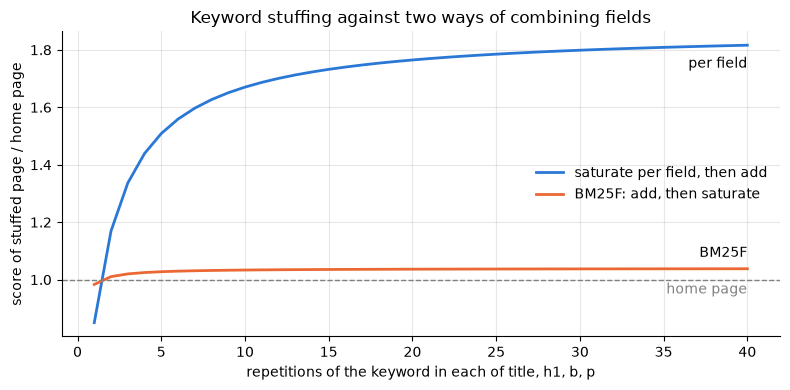

In [12]:
reps = np.arange(1, 41)
ratio_per_field = [per_field(dict.fromkeys(stuffed_4, r)) / per_field(home) for r in reps]
ratio_bm25f = [bm25f(dict.fromkeys(stuffed_4, r))[0] / bm25f(home)[0] for r in reps]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(reps, ratio_per_field, color="#2a78d6", lw=2, label="saturate per field, then add")
ax.plot(reps, ratio_bm25f, color="#eb6834", lw=2, label="BM25F: add, then saturate")
ax.axhline(1, color="gray", lw=1, ls="--")
ax.text(40, 0.99, "home page", color="gray", ha="right", va="top")
ax.text(40, ratio_per_field[-1] - 0.04, "per field", ha="right", va="top")
ax.text(40, ratio_bm25f[-1] + 0.03, "BM25F", ha="right", va="bottom")
ax.set_xlabel("repetitions of the keyword in each of title, h1, b, p")
ax.set_ylabel("score of stuffed page / home page")
ax.set_title("Keyword stuffing against two ways of combining fields")
ax.grid(True, alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="center right", frameon=False)
plt.tight_layout()
plt.show()

With separate saturation, the stuffed page overtakes the home page after a few repetitions and
keeps gaining until it is almost twice as high. With BM25F, all repetitions run into the same
saturation limit, and the stuffed page never gains more than a few percent.

## 3. Anchor Text

The anchor text of a link describes the *target* page in the words of someone else. When the
crawler parses a page, it stores each link with its anchor text under the target URL. After
the crawl, an **anchor index** describes each target by all the anchor texts that point to it.
A few links, in the spirit of the book's Wikipedia and Erasmus examples:

In [13]:
links = [  # (source page, target page, anchor text)
    ("en.wikipedia.org/wiki/List_of_universities_in_Switzerland", "unibas.ch", "University of Basel"),
    ("de.wikipedia.org/wiki/Liste_der_Hochschulen_in_der_Schweiz", "unibas.ch", "Universität Basel"),
    ("erasmus-portal.eu/partners/ch", "unibas.ch", "University of Basel"),
    ("studyinswitzerland.ch/universities", "unibas.ch", "uni basel"),
    ("basel-news.ch/article/4711", "unibas.ch", "click here"),
    ("students-blog.ch/my-semester", "dmi.unibas.ch/mmir", "the multimedia retrieval course at uni basel"),
]

anchor_index = defaultdict(list)
for source, target, anchor in links:
    anchor_index[target].append(anchor)

print_table(
    [[target, len(anchors), ", ".join(anchors)] for target, anchors in anchor_index.items()],
    headers=["target page", "anchors", "anchor document"],
)

| target page        |   anchors | anchor document                                                                    |
|:-------------------|----------:|:-----------------------------------------------------------------------------------|
| unibas.ch          |         5 | University of Basel, Universität Basel, University of Basel, uni basel, click here |
| dmi.unibas.ch/mmir |         1 | the multimedia retrieval course at uni basel                                       |

The home page is described as "University of Basel" by pages its authors do not control. The
generic "click here" carries no information, but with thousands of links the useful
descriptions dominate.

How fast should the anchor score grow with the number $n$ of matching anchors? Many
independent votes are exactly the evidence we want, so the saturation must be gentler than
BM25's:

In [14]:
counts = [1, 10, 100, 1_000, 10_000, 100_000]
print_table(
    [[f"{n:,}", saturate(n), math.log(1 + n)] for n in counts],
    headers=["n anchors", "BM25 saturation (k1 = 1.2)", "log(1 + n)"],
    floatfmt=("", ".3f", ".2f"),
)

|   n anchors |   BM25 saturation (k1 = 1.2) |   log(1 + n) |
|------------:|-----------------------------:|-------------:|
|           1 |                        1.000 |         0.69 |
|          10 |                        1.964 |         2.40 |
|         100 |                        2.174 |         4.62 |
|       1,000 |                        2.197 |         6.91 |
|      10,000 |                        2.200 |         9.21 |
|     100,000 |                        2.200 |        11.51 |

BM25 saturation is flat after about 10 anchors; $\log(1 + n)$ keeps growing, only more slowly.

### Google bombs and one vote per domain

An unbounded score invites manipulation. In the book's example, the university home page
receives 12,000 anchors containing "uni basel" from 900 different domains. A spammer places
"uni basel" in 50,000 anchors on 3 domains, all pointing to their own page. We generate anchor
records with exactly these counts:

In [15]:
rng = np.random.default_rng(42)

def anchor_records(n_anchors, n_domains, prefix):
    """n_anchors (domain, anchor) records spread over n_domains; every domain links at least once."""
    ids = np.concatenate([np.arange(n_domains), rng.integers(0, n_domains, n_anchors - n_domains)])
    return [(f"{prefix}{k}.example", "uni basel") for k in ids]

inbound = {
    "home page": anchor_records(12_000, 900, "site"),
    "spam page": anchor_records(50_000, 3, "spam"),
}

anchor_rows, anchor_scores = [], {}
for page, records in inbound.items():
    n_anchors = len(records)
    n_domains = len({domain for domain, _ in records})
    anchor_scores[page] = (math.log(1 + n_anchors), math.log(1 + n_domains))
    anchor_rows.append([page, f"{n_anchors:,}", f"{n_domains:,}", *anchor_scores[page]])
print_table(anchor_rows, headers=["page", "anchors", "domains",
                           "score: all anchors", "score: one vote per domain"],
            floatfmt=".2f")

| page      |   anchors |   domains |   score: all anchors |   score: one vote per domain |
|:----------|----------:|----------:|---------------------:|-----------------------------:|
| home page |    12,000 |       900 |                 9.39 |                         6.80 |
| spam page |    50,000 |         3 |                10.82 |                         1.39 |

Counting all anchors, the spam page wins. Counting one vote per domain, the home page wins by
a wide margin. To match the home page, the spammer needs as many independent domains as the
university has, and those are expensive to fake.

## Location, Language, and Quality

The book lists three more signals: the location of user and page, the language of user and
page, and quality and trust. They have no single formula. Each becomes a feature, for example
"distance to the user in km", "page language equals query language", or "site trust score", and
the ranker learns from data how much each feature counts for which kind of query. That is the
topic of learning to rank (ch08-03).

## Payoff: the SEO Tricks, Checked

The chapter opener named the core problem of the web: no editor, and every signal that rewards
a page invites someone to fake it. Here are the results of this notebook side by side, each
time for a cheap trick against a naive score and against the score the book recommends:

In [16]:
stuffed_naive, home_naive = per_field(stuffed_4), per_field(home)
stuffed_bm25f, home_bm25f = bm25f(stuffed_4)[0], bm25f(home)[0]
bomb, uni = anchor_scores["spam page"], anchor_scores["home page"]

print_table(
    [
        ["names far apart (marathon result list)",
         f"pairs: {len(merged_pairs(m_hits))} vs {len(merged_pairs(hits))}",
         f"proximity: {m_score} vs {score}"],
        ["keyword stuffing (10x in 4 fields)", f"per field: {stuffed_naive:.2f} vs {home_naive:.2f}",
         f"BM25F: {stuffed_bm25f:.3f} vs {home_bm25f:.3f}"],
        ["Google bomb (50,000 anchors, 3 domains)", f"all anchors: {bomb[0]:.2f} vs {uni[0]:.2f}",
         f"per domain: {bomb[1]:.2f} vs {uni[1]:.2f}"],
    ],
    headers=["trick", "naive score: trick vs honest page", "robust score: trick vs honest page"],
)

| trick                                   | naive score: trick vs honest page   | robust score: trick vs honest page   |
|:----------------------------------------|:------------------------------------|:-------------------------------------|
| names far apart (marathon result list)  | pairs: 11 vs 3                      | proximity: 0 vs 178                  |
| keyword stuffing (10x in 4 fields)      | per field: 41.25 vs 24.70           | BM25F: 2.188 vs 2.117                |
| Google bomb (50,000 anchors, 3 domains) | all anchors: 10.82 vs 9.39          | per domain: 1.39 vs 6.80             |

<div style="border-left: 4px solid #C8102E; background: rgba(200, 16, 46, 0.06); padding: 0.6em 0.9em; margin: 0.6em 0; border-radius: 4px;">
<strong style="color:#C8102E; text-transform:uppercase; font-size:0.78em; letter-spacing:0.06em;">Make repetition expensive</strong><br>
Each content signal is designed so that cheap repetition does not pay. Proximity rewards terms that occur together, not terms that occur often. BM25F weights the fields first and saturates once, so stuffing more fields hits the same limit. Anchor text counts one vote per domain, so a million links from three sites stay three votes.
</div>

## Summary

Web search extends BM25 with signals about *where* the terms occur and *what others say*
about a page. Proximity merges the positional hit lists, pairs neighbouring hits of different terms, and bins their distances.
BM25F adds field-weighted counts and then saturates once. The anchor index describes a page
by the links that point to it, with a gentle $\log(1 + n)$ growth and one vote per domain.
How to combine these signals with PageRank (ch08-02) into one ranking is the topic of
learning to rank (ch08-03).

## Try it yourself

1. **In-order bonus.** Change `proximity_score` so that reversed pairs count only half. How
   does the score for "us open" change? Try `proximity_of_text` with other names from the
   article, such as "rafael nadal" or "andy murray".
2. **Field weights.** Set the title weight to 1, the same as `<p>`. How close does the blog
   post with nine paragraph occurrences now come to the home page?
3. **Bomb budget.** How many independent domains does the spammer need so that
   $\log(1 + n_{\text{domains}})$ beats the home page? Change the arguments of
   `anchor_records` and re-run the table.